In [27]:
import numpy as np
import pandas as pd
from scipy.sparse import issparse

def get_cluster_specific_genes(adata, cluster_key, min_log_mean=0.5, min_pct_in_cluster=0.1):
    """
    Return a list of cluster-specific genes for each cluster, sorted by specificity in descending order.
    
    Parameters
    ----------
    adata : AnnData
        AnnData object with raw counts.
    cluster_key : str
        Column name in adata.obs that stores cluster labels.
    min_log_mean : float, default 0.5
        Minimum threshold for log1p(mean expression) within the target cluster.
    min_pct_in_cluster : float, default 0.1
        Minimum fraction of cells expressing the gene within the target cluster.
    
    Returns
    -------
    dict
        {cluster_id: pd.DataFrame with columns ['gene', 'specificity', 'log_mean_target', 'pct_target']}
    """
    # Obtain the expression matrix after log1p normalization
    X = adata.X
    if issparse(X):
        X = X.toarray()
    sc.pp.normalize_total(adata, target_sum=1e6)
    X_log = np.log1p(X)
    
    clusters = adata.obs[cluster_key].values
    unique_clusters = np.unique(clusters)
    gene_names = adata.var_names.values
    
    n_cells, n_genes = X.shape
    
    # Precompute the mean expression and detection rate for each gene in each cluster
    mean_expr = {}
    pct_expr = {}
    for cl in unique_clusters:
        mask = (clusters == cl)
        expr_cl = X[mask]  # raw counts
        mean_expr[cl] = X_log[mask].mean(axis=0)  # mean of log1p-transformed expression
        pct_expr[cl] = (expr_cl > 0).mean(axis=0)  # detection rate based on raw counts > 0

    # Store results
    cluster_marker_dict = {}

    for target_cl in unique_clusters:
        # Mean expression in the target cluster
        mu_target = mean_expr[target_cl]  # shape: (n_genes,)
        pct_target = pct_expr[target_cl]

        # Maximum mean expression across other clusters
        other_clusters = [c for c in unique_clusters if c != target_cl]
        if len(other_clusters) == 0:
            max_other = np.zeros_like(mu_target)
        else:
            other_means = np.stack([mean_expr[c] for c in other_clusters])  # (n_other, n_genes)
            max_other = other_means.max(axis=0)

        # Specificity score: mu_target / (mu_target + max_other + 1e-9)
        specificity = mu_target / (mu_target + max_other + 1e-9)

        # Build DataFrame
        df = pd.DataFrame({
            'gene': gene_names,
            'specificity': specificity,
            'log_mean_target': mu_target,
            'pct_target': pct_target
        })

        # Filter: sufficiently expressed and detected in enough cells
        df_filtered = df[
            (df['log_mean_target'] >= min_log_mean) &
            (df['pct_target'] >= min_pct_in_cluster)
        ].sort_values('specificity', ascending=False).reset_index(drop=True)

        cluster_marker_dict[target_cl] = df_filtered

    return cluster_marker_dict

In [28]:
import scanpy as sc
adata_B = sc.read("./h5ad/adata_B.h5ad")

In [29]:
marker_dict = get_cluster_specific_genes(adata_B[adata_B.obs["batch"]=="H-nS06"],"celltype")
print(marker_dict['Stress-Activated B'].head(10)[['gene', 'specificity', 'log_mean_target', 'pct_target']])

/home/pyc/miniconda3/envs/sc-analysis/lib/python3.9/site-packages/scanpy/preprocessing/_normalization.py:207: UserWarning: Received a view of an AnnData. Making a copy.
  view_to_actual(adata)


        gene  specificity  log_mean_target  pct_target
0    IGKV1-6     0.857754         0.639851    0.531353
1   IGHV1-46     0.792277         0.982455    0.640264
2  LINC01781     0.669375         0.565576    0.567657
3      SNED1     0.655516         0.767692    0.673267
4       NEK1     0.616992         0.820004    0.627063
5      ALG13     0.596875         0.846791    0.656766
6       CHD2     0.579232         1.032195    0.815182
7    C9orf72     0.569103         0.574126    0.531353
8     CCSER1     0.568408         0.690425    0.636964
9    ANKRD37     0.558959         0.982066    0.768977


Computing mean expression using the following genes: ['IGKV1-6', 'IGHV1-46', 'LINC01781', 'SNED1', 'NEK1', 'ALG13', 'CHD2', 'C9orf72', 'CCSER1', 'ANKRD37']
Mean log expression saved to adata_B.obs['mean_log_IGKV1-6_IGHV1-46_LINC01781_etc']
95% confidence ellipse drawn (n=303)


/tmp/ipykernel_1290526/2167315901.py:42: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  adata_B.obs[col_name] = mean_log_expr


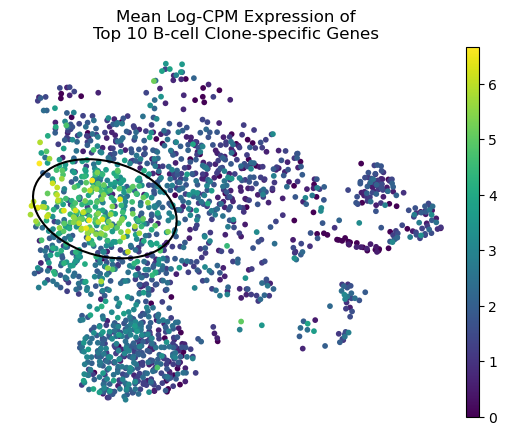

In [38]:
import scanpy as sc
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import chi2
from matplotlib.patches import Ellipse

# >>>>>>>>>> User-modifiable parameters <<<<<<<<<<
TARGET_CELLTYPE = 'Stress-Activated B'   # ← Cell type for which to draw the ellipse
ELLIPSE_LINEWIDTH = 1.5        # ← Ellipse line width
ELLIPSE_LINECOLOR = "black"    # ← Ellipse line color
# ====================================

adata_B = sc.read("./h5ad/adata_B.h5ad")
adata_B = adata_B[adata_B.obs["batch"] == "H-nS06"]

gene_list = ['IGKV1-6', 'IGHV1-46', 'LINC01781', 'SNED1', "NEK1",
             "ALG13", "CHD2", "C9orf72", "CCSER1", "ANKRD37"]

available_genes = [g for g in gene_list if g in adata_B.var_names]
missing_genes = [g for g in gene_list if g not in adata_B.var_names]

if missing_genes:
    print(f"Warning: The following genes are not in the data and have been ignored: {missing_genes}")
if not available_genes:
    raise ValueError("None of the genes in the provided list are present in adata.var_names!")

print(f"Computing mean expression using the following genes: {available_genes}")

adata_temp = adata_B.copy()
sc.pp.normalize_total(adata_temp, target_sum=1e6)
sc.pp.log1p(adata_temp)

gene_expr = adata_temp[:, available_genes].X
if hasattr(gene_expr, "toarray"):
    gene_expr = gene_expr.toarray()

mean_log_expr = np.mean(gene_expr, axis=1)

col_name = (f"mean_log_{'_'.join(available_genes[:3])}"
            + ("_etc" if len(available_genes) > 3 else ""))
adata_B.obs[col_name] = mean_log_expr
print(f"Mean log expression saved to adata_B.obs['{col_name}']")

# 7. Plot on UMAP (original code preserved)
sc.pl.umap(
    adata_B,
    color=col_name,
    cmap='viridis',
    frameon=False,
    legend_loc='right margin',
    title=f"Mean Log-CPM Expression of\nTop {len(available_genes)} B-cell Clone-specific Genes",
    colorbar_loc="right",
    show=False
)

# === Only this section added: draw the ellipse ===
mask = adata_B.obs["celltype"] == TARGET_CELLTYPE
if mask.sum() >= 3:
    umap_coords = adata_B[mask].obsm["X_umap"]
    mu = umap_coords.mean(axis=0)
    cov = np.cov(umap_coords, rowvar=False)
    chi2_val = chi2.ppf(0.9, df=2)
    eigvals, eigvecs = np.linalg.eigh(cov)
    width  = 2 * np.sqrt(chi2_val * eigvals[1])
    height = 2 * np.sqrt(chi2_val * eigvals[0])
    angle = np.degrees(np.arctan2(eigvecs[1, 1], eigvecs[0, 1]))
    ellipse = Ellipse(xy=mu, width=width, height=height, angle=angle,
                      fill=False, edgecolor=ELLIPSE_LINECOLOR, linewidth=ELLIPSE_LINEWIDTH)
    plt.gca().add_patch(ellipse)
    print(f"95% confidence ellipse drawn (n={mask.sum()})")
else:
    print(f"Cell type '{TARGET_CELLTYPE}' has too few cells; skipping ellipse")
# ============================
plt.show()

In [31]:
adata_HD = sc.read("./h5ad/adata_HD.h5ad")

In [32]:
adata_HD = adata_HD[adata_HD.obs["batch"]=="nS06"]

Plotting 31176 spots, alpha range: 0.00 - 1.00


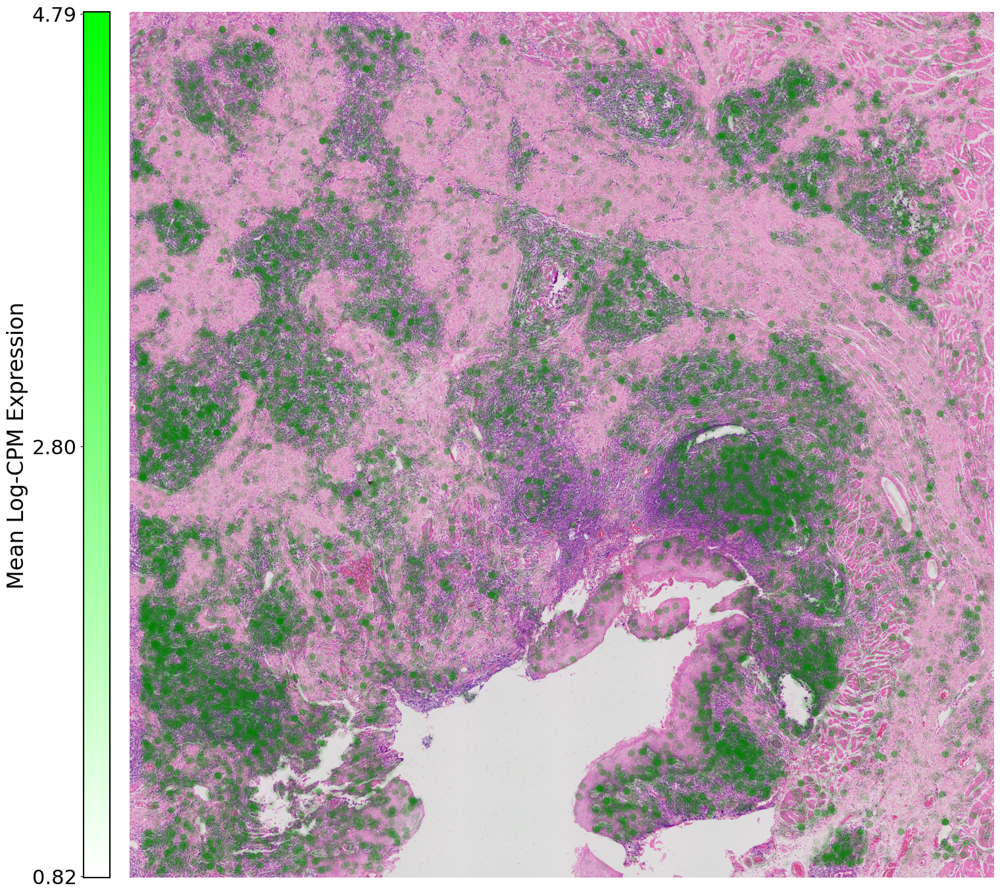

In [33]:
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import numpy as np
from PIL import Image

# === 1. Setup and read the image ===
Image.MAX_IMAGE_PIXELS = None
image_path = '../20250410-L25-015607-9.tif'
img = mpimg.imread(image_path)

# === 2. Compute a score for each spot ===
gene_list = ['IGKV1-6', 'IGHV1-46', 'LINC01781', 'SNED1', "NEK1",
             "ALG13", "CHD2", "C9orf72", "CCSER1", "ANKRD37"]

# 1. Filter for valid genes
valid_genes = [g for g in gene_list if g in adata_HD.var_names]
if not valid_genes:
    raise ValueError("Genes in the gene list are not present in adata")

# 2. Prepare data
adata_plot = adata_HD.copy()
sc.pp.normalize_total(adata_plot, target_sum=1e6)
sc.pp.log1p(adata_plot)

# 2. Extract spatial coordinates and expression submatrix
all_coords = adata_plot.obsm["spatial"]
sub_matrix = adata_plot[:, valid_genes].X

# 3. Convert to a dense array
if hasattr(sub_matrix, 'toarray'):
    dense_data = sub_matrix.toarray()
else:
    dense_data = np.array(sub_matrix)

# 4. Compute the mean expression per spot
gene_scores = np.mean(dense_data, axis=1)

# === 3. Core modification: handle transparency (alpha) ===
# Only plot spots with expression > 0 to avoid invisible points across the whole image
valid_indices = gene_scores > 0
plot_coords = all_coords[valid_indices]
plot_scores = gene_scores[valid_indices]

# Normalize alpha values to the range [0, 1]
# Logic: (current value - min) / (max - min)
# Lowest score -> alpha=0 (fully transparent), highest score -> alpha=1 (fully opaque)
min_score = plot_scores.min()
max_score = plot_scores.max()

if max_score > min_score:
    alphas = (plot_scores - min_score) / (max_score - min_score)
else:
    alphas = np.ones_like(plot_scores)  # Avoid division by zero when max equals min

# Optional: set a minimum alpha floor, e.g., 0.1, so that low-score spots remain faintly visible
# alphas = 0.1 + 0.9 * alphas 

print(f"Plotting {len(plot_scores)} spots, alpha range: {alphas.min():.2f} - {alphas.max():.2f}")

# === 4. Compute the bounding box ===
all_x = plot_coords[:, 0]
all_y = plot_coords[:, 1]

margin = 50
x_min, x_max = np.min(all_x) - margin, np.max(all_x) + margin
y_min, y_max = np.min(all_y) - margin, np.max(all_y) + margin

x_min, y_min = max(0, x_min), max(0, y_min)

x_min_px, x_max_px = int(x_min), int(x_max)
y_min_px, y_max_px = int(y_min), int(y_max)

# Crop the image
cropped_img = img[y_min_px:y_max_px, x_min_px:x_max_px]

# Adjust coordinates relative to the cropped image
final_x = all_x - x_min
final_y = all_y - y_min

# === 5. Plotting ===
fig, ax = plt.subplots(figsize=(15, 15))

# 1. Display the cropped background image and hide the axes
ax.imshow(cropped_img)
ax.axis('off')

# 2. Overlay scatter points with fixed green color and dynamic alpha
scatter = ax.scatter(final_x, final_y, c='green', alpha=alphas, s=60, edgecolors='none')

# 3. Add an alpha-gradient color bar on the left
from mpl_toolkits.axes_grid1 import make_axes_locatable
divider = make_axes_locatable(ax)
# [Widen] increase size from 2% to 4%
cax = divider.append_axes("left", size="3%", pad=0.3)

# Construct an RGBA gradient array (bottom to top: alpha 0 -> 1)
N = 256
rgba_bar = np.zeros((N, 1, 4))
rgba_bar[:, 0, 1] = 1.0  # Full green channel (bright green)
rgba_bar[:, 0, 3] = np.linspace(0, 1, N)  # Alpha from 0 to 1

# Flip the array so that the bottom becomes solid green and the top becomes transparent
cax.imshow(np.flip(rgba_bar, axis=0), aspect='auto')

# [Fully fix tick and label positions]
cax.set_yticks([0, N // 2, N - 1]) 
cax.set_yticklabels([f'{plot_scores.max():.2f}',     # Bottom (index 0) shows the maximum
                     f'{(plot_scores.min() + plot_scores.max()) / 2:.2f}',  # Middle shows the median
                     f'{plot_scores.min():.2f}'],     # Top (index 255) shows the minimum
                    fontsize=14)

# Set the left-side label
cax.set_ylabel('Mean Log-CPM Expression', fontsize=24)

# Completely hide the horizontal axis and polish the vertical ticks
cax.tick_params(axis='x', bottom=False, top=False, labelbottom=False, labeltop=False)
cax.tick_params(axis='y', labelleft=True, labelsize=22, pad=4)

# [Add a black frame] instead of hiding the border, set a solid black border
for spine in cax.spines.values():
    spine.set_visible(True)
    spine.set_color('black')
    spine.set_linewidth(1.5)
plt.tight_layout(pad=0)
plt.show()

In [17]:
adata_T = sc.read("./h5ad/adata_T.h5ad")

In [37]:
marker_dict = get_cluster_specific_genes(adata_T[adata_T.obs["batch"]=="H-nS06"],"celltype")
print(marker_dict['Effector Memory Cd8⁺ T Cell'].head(10)[['gene', 'specificity', 'log_mean_target', 'pct_target']])

/home/pyc/miniconda3/envs/sc-analysis/lib/python3.9/site-packages/scanpy/preprocessing/_normalization.py:207: UserWarning: Received a view of an AnnData. Making a copy.
  view_to_actual(adata)


      gene  specificity  log_mean_target  pct_target
0     GZMK     0.572240         1.471955    0.945466
1   TNFSF9     0.565769         0.741665    0.622067
2   CCL4L2     0.553739         2.030008    0.819911
3     CCL4     0.530880         2.506732    0.893469
4   CCL3L3     0.516207         1.092383    0.642359
5    CRTAM     0.492495         1.102276    0.724160
6    SRSF7     0.491930         1.478499    0.939759
7  HERPUD2     0.487320         0.572911    0.545973
8     AOAH     0.486510         0.688995    0.658212
9     CCL5     0.485508         2.220909    0.979708


Computing mean expression using the following genes: ['GZMK', 'TNFSF9', 'CCL4L2', 'CCL4', 'CCL3L3', 'CRTAM', 'SRSF7', 'HERPUD2', 'AOAH', 'CCL5']
Mean log expression saved to adata_T.obs['mean_log_GZMK_TNFSF9_CCL4L2_etc']
95% confidence ellipse drawn (n=1577)


/tmp/ipykernel_1290526/46565024.py:42: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  adata_T.obs[col_name] = mean_log_expr


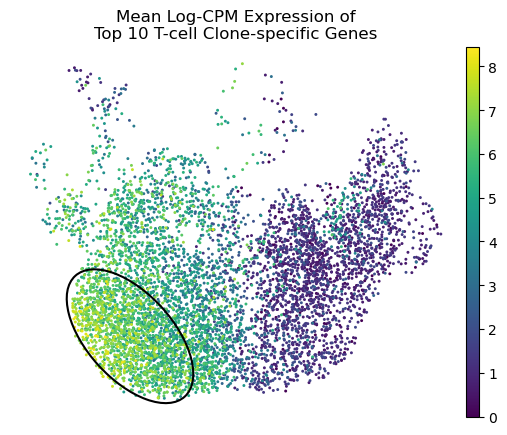

In [43]:
import scanpy as sc
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import chi2
from matplotlib.patches import Ellipse

# >>>>>>>>>> User-modifiable parameters <<<<<<<<<<
TARGET_CELLTYPE = 'Effector Memory Cd8⁺ T Cell'   # ← Cell type for which to draw the ellipse
ELLIPSE_LINEWIDTH = 1.5        # ← Ellipse line width
ELLIPSE_LINECOLOR = "black"    # ← Ellipse line color
# ====================================

adata_T = sc.read("./h5ad/adata_T.h5ad")
adata_T = adata_T[adata_T.obs["batch"] == "H-nS06"]

gene_list = ['GZMK', 'TNFSF9', 'CCL4L2', 'CCL4', "CCL3L3",
             "CRTAM", "SRSF7", "HERPUD2", "AOAH", "CCL5"]

available_genes = [g for g in gene_list if g in adata_T.var_names]
missing_genes = [g for g in gene_list if g not in adata_T.var_names]

if missing_genes:
    print(f"Warning: The following genes are not in the data and have been ignored: {missing_genes}")
if not available_genes:
    raise ValueError("None of the genes in the provided list are present in adata.var_names!")

print(f"Computing mean expression using the following genes: {available_genes}")

adata_temp = adata_T.copy()
sc.pp.normalize_total(adata_temp, target_sum=1e6)
sc.pp.log1p(adata_temp)

gene_expr = adata_temp[:, available_genes].X
if hasattr(gene_expr, "toarray"):
    gene_expr = gene_expr.toarray()

mean_log_expr = np.mean(gene_expr, axis=1)

col_name = (f"mean_log_{'_'.join(available_genes[:3])}"
            + ("_etc" if len(available_genes) > 3 else ""))
adata_T.obs[col_name] = mean_log_expr
print(f"Mean log expression saved to adata_T.obs['{col_name}']")

# 7. Plot on UMAP (original code preserved)
sc.pl.umap(
    adata_T,
    color=col_name,
    cmap='viridis',
    frameon=False,
    legend_loc='right margin',
    title=f"Mean Log-CPM Expression of\nTop {len(available_genes)} T-cell Clone-specific Genes",
    colorbar_loc="right",
    show=False
)

# === Only this section added: draw the ellipse ===
mask = adata_T.obs["celltype"] == TARGET_CELLTYPE
if mask.sum() >= 3:
    umap_coords = adata_T[mask].obsm["X_umap"]
    mu = umap_coords.mean(axis=0)
    cov = np.cov(umap_coords, rowvar=False)
    chi2_val = chi2.ppf(0.9, df=2)
    eigvals, eigvecs = np.linalg.eigh(cov)
    width  = 2 * np.sqrt(chi2_val * eigvals[1])
    height = 2 * np.sqrt(chi2_val * eigvals[0])
    angle = np.degrees(np.arctan2(eigvecs[1, 1], eigvecs[0, 1]))
    ellipse = Ellipse(xy=mu, width=width, height=height, angle=angle,
                      fill=False, edgecolor=ELLIPSE_LINECOLOR, linewidth=ELLIPSE_LINEWIDTH)
    plt.gca().add_patch(ellipse)
    print(f"95% confidence ellipse drawn (n={mask.sum()})")
else:
    print(f"Cell type '{TARGET_CELLTYPE}' has too few cells; skipping ellipse")
# ============================
plt.show()

In [44]:
adata_HD = sc.read("./h5ad/adata_HD.h5ad")

In [45]:
adata_HD = adata_HD[adata_HD.obs["batch"]=="nS06"]

Plotting 73824 spots, alpha range: 0.00 - 1.00


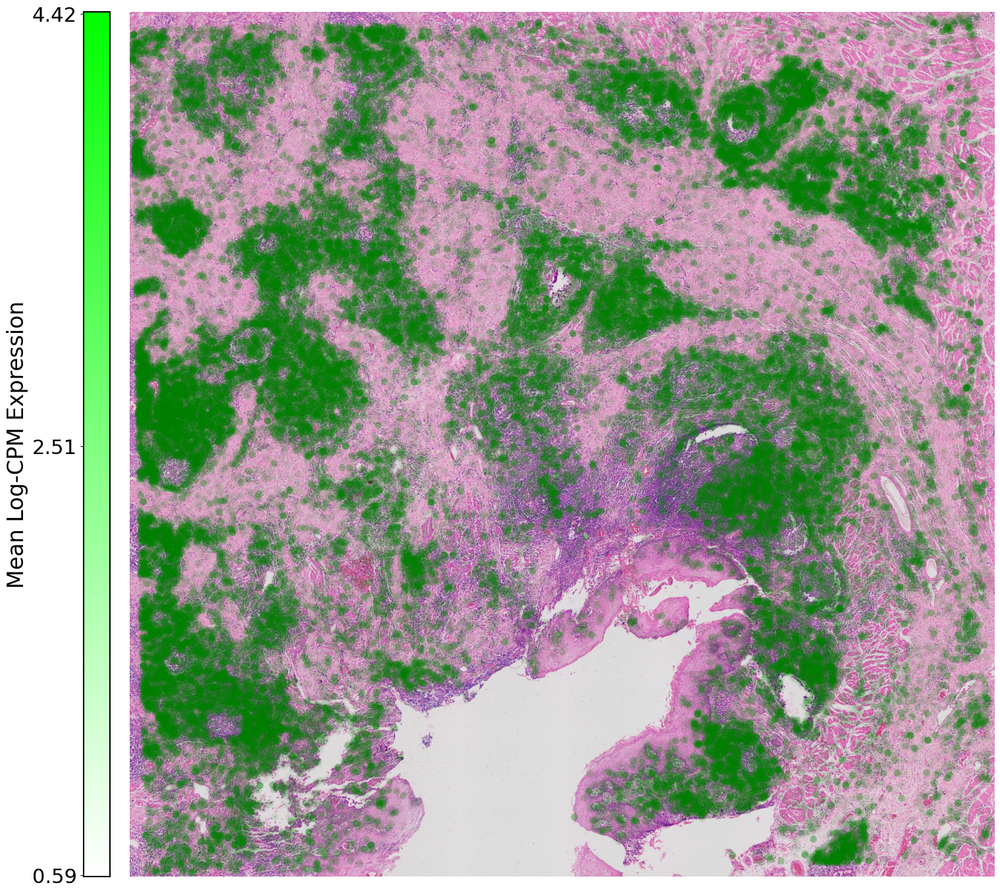

In [46]:
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import numpy as np
from PIL import Image

# === 1. Setup and read the image ===
Image.MAX_IMAGE_PIXELS = None
image_path = '../20250410-L25-015607-9.tif'
img = mpimg.imread(image_path)

# === 2. Compute a score for each spot ===
gene_list = ['GZMK', 'TNFSF9', 'CCL4L2', 'CCL4', "CCL3L3",
             "CRTAM", "SRSF7", "HERPUD2", "AOAH", "CCL5"]

# 1. Filter for valid genes
valid_genes = [g for g in gene_list if g in adata_HD.var_names]
if not valid_genes:
    raise ValueError("Genes in the gene list are not present in adata")

# 2. Prepare data
adata_plot = adata_HD.copy()
sc.pp.normalize_total(adata_plot, target_sum=1e6)
sc.pp.log1p(adata_plot)

# 2. Extract spatial coordinates and expression submatrix
all_coords = adata_plot.obsm["spatial"]
sub_matrix = adata_plot[:, valid_genes].X

# 3. Convert to a dense array
if hasattr(sub_matrix, 'toarray'):
    dense_data = sub_matrix.toarray()
else:
    dense_data = np.array(sub_matrix)

# 4. Compute the mean expression per spot
gene_scores = np.mean(dense_data, axis=1)

# === 3. Core modification: handle transparency (alpha) ===
# Only plot spots with expression > 0 to avoid invisible points across the whole image
valid_indices = gene_scores > 0
plot_coords = all_coords[valid_indices]
plot_scores = gene_scores[valid_indices]

# Normalize alpha values to the range [0, 1]
# Logic: (current value - min) / (max - min)
# Lowest score -> alpha=0 (fully transparent), highest score -> alpha=1 (fully opaque)
min_score = plot_scores.min()
max_score = plot_scores.max()

if max_score > min_score:
    alphas = (plot_scores - min_score) / (max_score - min_score)
else:
    alphas = np.ones_like(plot_scores)  # Avoid division by zero when max equals min

# Optional: set a minimum alpha floor, e.g., 0.1, so that low-score spots remain faintly visible
# alphas = 0.1 + 0.9 * alphas 

print(f"Plotting {len(plot_scores)} spots, alpha range: {alphas.min():.2f} - {alphas.max():.2f}")

# === 4. Compute the bounding box ===
all_x = plot_coords[:, 0]
all_y = plot_coords[:, 1]

margin = 50
x_min, x_max = np.min(all_x) - margin, np.max(all_x) + margin
y_min, y_max = np.min(all_y) - margin, np.max(all_y) + margin

x_min, y_min = max(0, x_min), max(0, y_min)

x_min_px, x_max_px = int(x_min), int(x_max)
y_min_px, y_max_px = int(y_min), int(y_max)

# Crop the image
cropped_img = img[y_min_px:y_max_px, x_min_px:x_max_px]

# Adjust coordinates relative to the cropped image
final_x = all_x - x_min
final_y = all_y - y_min

# === 5. Plotting ===
fig, ax = plt.subplots(figsize=(15, 15))

# 1. Display the cropped background image and hide the axes
ax.imshow(cropped_img)
ax.axis('off')

# 2. Overlay scatter points with fixed green color and dynamic alpha
scatter = ax.scatter(final_x, final_y, c='green', alpha=alphas, s=60, edgecolors='none')

# 3. Add an alpha-gradient color bar on the left
from mpl_toolkits.axes_grid1 import make_axes_locatable
divider = make_axes_locatable(ax)
# [Widen] increase size from 2% to 4%
cax = divider.append_axes("left", size="3%", pad=0.3)

# Construct an RGBA gradient array (bottom to top: alpha 0 -> 1)
N = 256
rgba_bar = np.zeros((N, 1, 4))
rgba_bar[:, 0, 1] = 1.0  # Full green channel (bright green)
rgba_bar[:, 0, 3] = np.linspace(0, 1, N)  # Alpha from 0 to 1

# Flip the array so that the bottom becomes solid green and the top becomes transparent
cax.imshow(np.flip(rgba_bar, axis=0), aspect='auto')

# [Fully fix tick and label positions]
cax.set_yticks([0, N // 2, N - 1]) 
cax.set_yticklabels([f'{plot_scores.max():.2f}',     # Bottom (index 0) shows the maximum
                     f'{(plot_scores.min() + plot_scores.max()) / 2:.2f}',  # Middle shows the median
                     f'{plot_scores.min():.2f}'],     # Top (index 255) shows the minimum
                    fontsize=14)

# Set the left-side label
cax.set_ylabel('Mean Log-CPM Expression', fontsize=24)

# Completely hide the horizontal axis and polish the vertical ticks
cax.tick_params(axis='x', bottom=False, top=False, labelbottom=False, labeltop=False)
cax.tick_params(axis='y', labelleft=True, labelsize=22, pad=4)

# [Add a black frame] instead of hiding the border, set a solid black border
for spine in cax.spines.values():
    spine.set_visible(True)
    spine.set_color('black')
    spine.set_linewidth(1.5)
plt.tight_layout(pad=0)
plt.show()